# Wrappers de C para Python: histograma y Otsu sobre una plantilla

Máster en Inteligencia Artificial, Universidad de Murcia, curso 2026/27

El objetivo principal es compilar una biblioteca C y usarla desde Python con `ctypes`: declarar tipos, compartir arrays y gestionar la memoria. Usaremos como caso de prueba una plantilla planar. El pipeline de procesamiento consistirá en obtener la binarización de Otsu a partir de la imagen de grises, para después obtener el contorno de la componente conexa principal de la imagen binarizada, el cual será finalmente usado para la correspondiente rectificación.

En el [notebook 04](04_ImageProcessingForCV.ipynb) y el tema 03 desarrollamos el procesamiento de imagen básico involucrado. Aquí nos centraremos principalmente en la construcción del wrapper de C desde python.

## Entorno y datos

Funciona en CPU tanto en Jupyter local (Linux/WSL) como en Google Colab. Además del entorno base de [`README.md`](README.md), necesitará que `gcc` y `make` estén instalados en el sistema. En Ubuntu/WSL se proporcionan con `sudo apt install build-essential`. No se instalarán estos paquetes automáticamente. El ejemplo compila una biblioteca Linux `.so` (en otros sistemas habría que adaptar la compilación y la carga).

La primera ejecución descarga una fotografía y un vídeo; las siguientes reutilizarán los archivos. Datos y fuentes C generadas se guardan en `output/05_wrappers/` al ejecutar el notebook fuente. Se pueden eliminar con `make clean`.

In [1]:
import ctypes as ct
import subprocess
import sys
from pathlib import Path
from shutil import copyfileobj, which
from time import perf_counter
from urllib.request import urlopen

import cv2
import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import IntSlider, interact

try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

print("Entorno:", "Google Colab" if IN_COLAB else "Jupyter local")
print("Python:", sys.version.split()[0])
for tool in ("gcc", "make"):
    if which(tool) is None:
        raise RuntimeError(f"Falta {tool}; consulta la celda de entorno y README.md")

root = Path.cwd()
WORK_DIR = (root if root.name == "output" else root / "output") / "05_wrappers"
DATA_DIR = WORK_DIR / "data"
BUILD_DIR = WORK_DIR / "native"
DATA_DIR.mkdir(parents=True, exist_ok=True)
BUILD_DIR.mkdir(parents=True, exist_ok=True)

def download_if_missing(url, destination, minimum_size=1):
    destination = Path(destination)
    if destination.is_file() and destination.stat().st_size >= minimum_size:
        print(f"Ya existe: {destination.name}")
        return destination
    temporary = destination.with_suffix(destination.suffix + ".part")
    print(f"Descargando {destination.name}")
    try:
        with urlopen(url, timeout=60) as response, temporary.open("wb") as output:
            copyfileobj(response, output)
        if temporary.stat().st_size < minimum_size:
            raise RuntimeError(f"Descarga incompleta: {url}")
        temporary.replace(destination)
    finally:
        temporary.unlink(missing_ok=True)
    return destination

PHOTO = download_if_missing("https://ditec.um.es/~pedroe/fotoplantilla.png",
                            DATA_DIR / "fotoplantilla.png", minimum_size=1000)
VIDEO = download_if_missing("https://ditec.um.es/~pedroe/plantilla-L-15x15.mp4",
                            DATA_DIR / "plantilla-L-15x15.mp4", minimum_size=1000)
NFRAMES_DEMO = 30  # Aumentar, por ejemplo a 150, para explorar el video algo más.

Entorno: Jupyter local
Python: 3.11.11
Ya existe: fotoplantilla.png
Ya existe: plantilla-L-15x15.mp4


## Pipeline mínimo con OpenCV

Otsu elige el umbral que maximiza la separación entre las dos clases:

$$t^* = \arg\max_t \omega_0(t)\omega_1(t)(\mu_0(t)-\mu_1(t))^2.$$

Las clases son $I\leq t$ e $I>t$. Es útil con histogramas bimodales, pero no garantiza segmentación correcta bajo sombras o iluminación espacialmente variable (véase el umbralizado local del notebook 04).

La plantilla es oscura: invertimos la binarización para que sea el primer plano blanco. Elegimos el contorno externo de mayor **área**, no el de más puntos (su número depende de la aproximación). Descartamos contornos que tocan el borde de la imagen para excluir el fondo exterior oscuro. Es una simple heurística, no un detector general: otros objetos grandes, sombras u oclusiones podrían dominar. Las funciones de histograma y umbral son intercambiables para probar el wrapper.

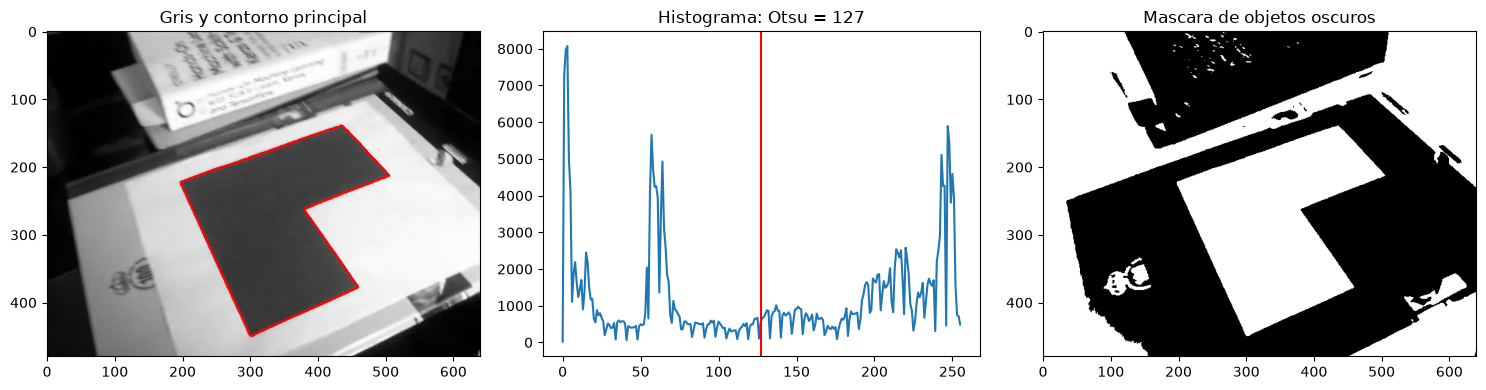

In [2]:
def gray_uint8(image):
    image = np.asarray(image)
    if image.ndim != 2 or image.dtype != np.uint8 or image.size == 0:
        raise ValueError("Se espera una imagen de gris uint8, 2D y no vacia")
    if image.size > np.iinfo(np.int32).max:
        raise ValueError("Imagen demasiado grande para los contadores int32")
    return np.ascontiguousarray(image)

def comp_histo_cv2(image):
    return cv2.calcHist([gray_uint8(image)], [0], None, [256], [0, 256]).ravel()

def comp_threshold_Otsu(hist, image):
    threshold, _ = cv2.threshold(image, 0, 255, cv2.THRESH_BINARY | cv2.THRESH_OTSU)
    return int(threshold)

def processing(image, comp_histo=comp_histo_cv2, comp_threshold=comp_threshold_Otsu):
    image = gray_uint8(image)
    hist = comp_histo(image)
    threshold = comp_threshold(hist, image)
    _, binary = cv2.threshold(image, threshold, 255, cv2.THRESH_BINARY_INV)
    contours, _ = cv2.findContours(binary, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    rows, cols = image.shape
    interior = []
    for contour in contours:
        x, y, w, h = cv2.boundingRect(contour)
        if x > 0 and y > 0 and x+w < cols and y+h < rows:
            interior.append(contour)
    contour = max(interior, key=cv2.contourArea) if interior else None
    return image, hist, threshold, binary, contour

photo_bgr = cv2.imread(str(PHOTO))
if photo_bgr is None:
    raise RuntimeError(f"OpenCV no puede leer {PHOTO}")
photo_gray = cv2.cvtColor(photo_bgr, cv2.COLOR_BGR2GRAY)
photo_result = processing(photo_gray)

def plot_result(result):
    image, hist, threshold, binary, contour = result
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    axes[0].imshow(image, cmap="gray", vmin=0, vmax=255)
    if contour is not None:
        points = contour[:, 0, :]
        points = np.vstack([points, points[0]])
        axes[0].plot(points[:, 0], points[:, 1], color="red")
    axes[0].set_title("Gris y contorno principal")
    axes[1].plot(hist)
    axes[1].axvline(threshold, color="red")
    axes[1].set_title(f"Histograma: Otsu = {threshold}")
    axes[2].imshow(binary, cmap="gray", vmin=0, vmax=255)
    axes[2].set_title("Mascara de objetos oscuros")
    fig.tight_layout()
    plt.show()

plot_result(photo_result)

## Rectificación de la plantilla

Una homografía transforma puntos con $(x',y',1)^T \sim H(x,y,1)^T$. Para mostrar un caso concreto fijamos cuatro correspondencias sobre la foto incluida: dos esquinas superiores y las dos del extremo inferior de la L. Sus posiciones de destino pertenecen a una L ideal de 300 × 300 píxeles, con brazos de 150 píxeles. No se estiman automáticamente desde el contorno.

`getPerspectiveTransform` calcula H y `warpPerspective` rectifica la imagen. La selección manual es aproximada y específica de esta foto; no elimina la distorsión de lente ni constituye una calibración métrica. En una aplicación real se podrían detectar e identificar las esquinas de forma aún más fiable (p.e., aproximando mucho mejor las esquinas, mediante intersección precisa de los segmentos rectos entre las esquinas aproximadas detectadas por el algoritmo de aproximación poligonal).

Desfase elegido: 1; error RMS de reproyeccion: 1.31 px


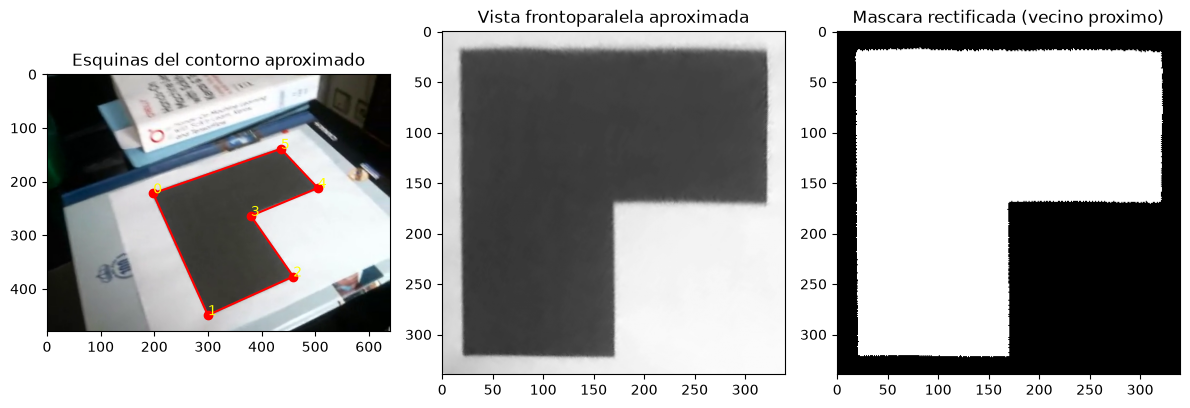

In [3]:
contour = photo_result[4]
if contour is None:
    raise RuntimeError("No se ha detectado el contorno de la plantilla")
polygon = cv2.approxPolyDP(contour, 0.02 * cv2.arcLength(contour, True), True)
if len(polygon) != 6:
    raise RuntimeError(f"Se esperaban 6 vertices de la L; detectados: {len(polygon)}")
vertices = polygon[:, 0, :].astype(np.float32)
# Modelo de la L en el orden del contorno externo de OpenCV; brazos de ancho 150.
dst = np.float32([[20, 20], [20, 320], [170, 320],
                  [170, 170], [320, 170], [320, 20]])
# El contorno puede empezar en cualquier vertice: probamos los seis desfases.
# Ajustamos con todos los puntos; con cuatro, cualquier correspondencia encajaria.
candidates = []
for shift in range(6):
    points = np.roll(vertices, -shift, axis=0)
    homography, _ = cv2.findHomography(points, dst, method=0)
    if homography is None or not np.isfinite(homography).all():
        continue
    if np.linalg.matrix_rank(homography) < 3:
        continue
    homogeneous = np.column_stack([points, np.ones(6)]) @ homography.T
    if np.any(np.abs(homogeneous[:, 2]) < 1e-10):
        continue
    projected = homogeneous[:, :2] / homogeneous[:, 2, None]
    error = np.sqrt(np.mean(np.sum((projected - dst)**2, axis=1)))
    if np.isfinite(error):
        candidates.append((error, shift, homography, points))
if not candidates:
    raise RuntimeError("No se pudo ajustar una homografia valida a la plantilla")
error, shift, H, src = min(candidates, key=lambda candidate: candidate[0])
print(f"Desfase elegido: {shift}; error RMS de reproyeccion: {error:.2f} px")
rectified = cv2.warpPerspective(photo_gray, H, (340, 340), borderValue=255)
rectified_mask = cv2.warpPerspective(photo_result[3], H, (340, 340),
                                     flags=cv2.INTER_NEAREST, borderValue=0)
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].imshow(cv2.cvtColor(photo_bgr, cv2.COLOR_BGR2RGB))
closed_polygon = np.vstack([vertices, vertices[0]])
axes[0].plot(closed_polygon[:, 0], closed_polygon[:, 1], color="red")
axes[0].scatter(src[:, 0], src[:, 1], color="red")
for i, (x, y) in enumerate(src):
    axes[0].text(x, y, str(i), color="yellow")
axes[0].set_title("Esquinas del contorno aproximado")
axes[1].imshow(rectified, cmap="gray", vmin=0, vmax=255)
axes[1].set_title("Vista frontoparalela aproximada")
axes[2].imshow(rectified_mask, cmap="gray", vmin=0, vmax=255)
axes[2].set_title("Mascara rectificada (vecino proximo)")
fig.tight_layout()
plt.show()

## Biblioteca C: histograma y umbral de Otsu

Primero escribimos la interfaz pública (`histo.h`). C recibe un puntero a
píxeles contiguos y su número. Reserva 256 contadores `int32_t` en una
estructura, y devuelve un código de estado: 0 si funciona, -1 si falla.
La función de liberación pertenece a la misma biblioteca que reservó la memoria.

Separar histograma y umbral permite reutilizar ambos. `otsu_c` recorre solo
256 niveles; ignora particiones con una clase vacía y conserva el primer
máximo en caso de empate. En imágenes constantes devuelve 0, como OpenCV.

In [4]:
header = r"""
#ifndef HISTO_H
#define HISTO_H
#include <stddef.h>
#include <stdint.h>

typedef struct { int32_t *hist; } THistogram;
int get_histogram_c(const uint8_t *image, size_t count, THistogram *out);
void free_mem_histogram_c(THistogram *out);
int otsu_c(const int32_t *hist);
#endif
"""
(BUILD_DIR / "histo.h").write_text(header.strip() + "\n", encoding="utf-8")

277

In [5]:
source = r"""
#include <stdlib.h>
#include "histo.h"

int get_histogram_c(const uint8_t *image, size_t count, THistogram *out)
{
    if (!out) return -1;
    out->hist = NULL;
    if (!image || !count || count > INT32_MAX) return -1;
    out->hist = calloc(256, sizeof(int32_t));
    if (!out->hist) return -1;
    for (size_t i = 0; i < count; ++i) out->hist[image[i]]++;
    return 0;
}

void free_mem_histogram_c(THistogram *out)
{
    if (out) { free(out->hist); out->hist = NULL; }
}

int otsu_c(const int32_t *hist)
{
    if (!hist) return -1;
    double total = 0, sum = 0;
    for (int i = 0; i < 256; ++i) {
        if (hist[i] < 0) return -1;
        total += hist[i];
        sum += (double)i * hist[i];
    }
    if (total == 0) return -1;
    double weight0 = 0, sum0 = 0, best = -1;
    int threshold = 0;
    for (int t = 0; t < 256; ++t) {
        weight0 += hist[t];
        sum0 += (double)t * hist[t];
        double weight1 = total - weight0;
        if (weight0 == 0 || weight1 == 0) continue;
        double delta = sum0 / weight0 - (sum - sum0) / weight1;
        double score = weight0 * weight1 * delta * delta;
        if (score > best) { best = score; threshold = t; }
    }
    return threshold;
}
"""
(BUILD_DIR / "histo.c").write_text(source.strip() + "\n", encoding="utf-8")

1212

## Compilación y carga

El Makefile generado vive exclusivamente en `BUILD_DIR`. `-fPIC` permite
crear una biblioteca compartida y `-O2` activa optimización. `subprocess.run`
con `check=True` propaga los errores de compilación a Jupyter y a `make`.
Reejecutar estas celdas recompila si cambia el fuente; si la biblioteca ya se
cargó en este kernel, reinicia el kernel para cargar la nueva versión.

In [6]:
makefile = """CC = gcc
CFLAGS = -std=c11 -O2 -Wall -Wextra -Werror -fPIC

.PHONY: all clean
all: libhisto.so

libhisto.so: histo.c histo.h
\t$(CC) $(CFLAGS) -shared -o $@ histo.c

clean:
\t$(RM) libhisto.so
"""
(BUILD_DIR / "Makefile").write_text(makefile, encoding="utf-8")
subprocess.run(["make", "-C", str(BUILD_DIR)], check=True)
lib = ct.CDLL(str((BUILD_DIR / "libhisto.so").resolve()))

make[1]: se entra en el directorio '/home/pedroe/rsyncdir/repositorios/va-master.git/practicas/notebooks/output/05_wrappers/native'
gcc -std=c11 -O2 -Wall -Wextra -Werror -fPIC -shared -o libhisto.so histo.c


make[1]: se sale del directorio '/home/pedroe/rsyncdir/repositorios/va-master.git/practicas/notebooks/output/05_wrappers/native'


## Prototipos y wrapper Python

`argtypes` y `restype` deben coincidir exactamente con C, incluido `None`
para `void`. `ndpointer` comprueba tipo y continuidad antes de pasar el puntero.
El wrapper acepta una ROI no contigua copiándola a memoria contigua, pero
rechaza floats, imágenes vacías y arrays que no sean de gris.

`as_array` crea una **vista** de la memoria C, sin copiarla. Copiamos el
resultado antes de liberarla: devolver la vista dejaría un puntero inválido.
El bloque `finally` libera la reserva incluso si falla la conversión.

In [7]:
class THistogram(ct.Structure):
    _fields_ = [("hist", ct.POINTER(ct.c_int32))]

lib.get_histogram_c.argtypes = [
    np.ctypeslib.ndpointer(dtype=np.uint8, ndim=2, flags="C_CONTIGUOUS"),
    ct.c_size_t, ct.POINTER(THistogram)]
lib.get_histogram_c.restype = ct.c_int
lib.free_mem_histogram_c.argtypes = [ct.POINTER(THistogram)]
lib.free_mem_histogram_c.restype = None
lib.otsu_c.argtypes = [
    np.ctypeslib.ndpointer(dtype=np.int32, ndim=1, shape=(256,), flags="C_CONTIGUOUS")]
lib.otsu_c.restype = ct.c_int

def comp_histo_C(image):
    image = gray_uint8(image)
    out = THistogram()
    try:
        status = lib.get_histogram_c(image, image.size, ct.byref(out))
        if status != 0:
            raise MemoryError("C no pudo reservar o calcular el histograma")
        return np.ctypeslib.as_array(out.hist, shape=(256,)).copy()
    finally:
        lib.free_mem_histogram_c(ct.byref(out))

def comp_threshold_C(hist, image):
    # El histograma procede de comp_histo_C; image conserva la interfaz del pipeline.
    hist = np.asarray(hist)
    if hist.shape != (256,) or hist.dtype != np.int32:
        raise ValueError("Se espera un histograma de 256 contadores int32")
    threshold = lib.otsu_c(np.ascontiguousarray(hist))
    if threshold < 0:
        raise ValueError("Histograma vacio o con contadores negativos")
    return threshold

## Validación antes de medir tiempos

Comparamos contadores con NumPy (enteros exactos) y OpenCV. Su histograma
usa `float32`, que pierde exactitud para contadores mayores que $2^{24}$;
las imágenes de esta prueba son pequeñas. También comprobamos umbral y máscara
frente a OpenCV en la foto, una ROI no contigua y casos sintéticos.

Las implementaciones pueden resolver de forma diferente empates numéricos
en histogramas casi simétricos: estas pruebas verifican los casos usados,
no una identidad universal bit a bit entre todos los backends de OpenCV.

Equivalencia verificada en 6 imagenes y entradas invalidas rechazadas


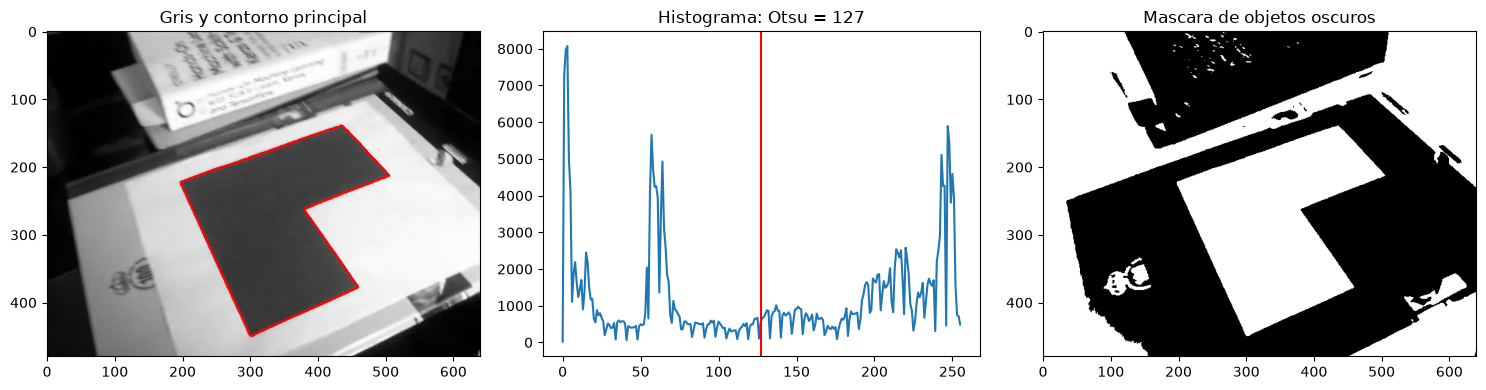

In [8]:
rng = np.random.default_rng(42)
test_images = [photo_gray, photo_gray[::2, ::2],
               np.zeros((8, 8), dtype=np.uint8),
               np.full((8, 8), 255, dtype=np.uint8),
               np.tile(np.array([20, 200], dtype=np.uint8), (32, 16)),
               rng.integers(0, 256, size=(64, 80), dtype=np.uint8)]
for image in test_images:
    native_hist = comp_histo_C(image)
    np.testing.assert_array_equal(native_hist, np.bincount(image.ravel(), minlength=256))
    np.testing.assert_array_equal(native_hist, comp_histo_cv2(image))
    native = processing(image, comp_histo_C, comp_threshold_C)
    reference = processing(image)
    assert native[2] == reference[2], (native[2], reference[2])
    np.testing.assert_array_equal(native[3], reference[3])

for invalid in [np.zeros((2, 2), dtype=float), np.empty((0, 2), dtype=np.uint8),
                np.zeros((2, 2, 3), dtype=np.uint8)]:
    try:
        comp_histo_C(invalid)
    except ValueError:
        pass
    else:
        raise AssertionError("El wrapper debe rechazar esta entrada")

for invalid_hist in [np.zeros(256, dtype=np.int32), -np.ones(256, dtype=np.int32)]:
    try:
        comp_threshold_C(invalid_hist, None)
    except ValueError:
        pass
    else:
        raise AssertionError("El wrapper debe rechazar este histograma")

print(f"Equivalencia verificada en {len(test_images)} imagenes y entradas invalidas rechazadas")
plot_result(processing(photo_gray, comp_histo_C, comp_threshold_C))

## Vídeo e interactividad

Leemos solo `NFRAMES_DEMO` frames y liberamos siempre `VideoCapture`.
El slider explora resultados ya calculados; la ejecución por `nbconvert`
produce una figura inicial y continúa sin esperar al usuario.

In [9]:
def read_frames(videofile, nframes):
    capture = cv2.VideoCapture(str(videofile))
    frames = []
    try:
        if not capture.isOpened():
            raise RuntimeError(f"OpenCV no puede abrir {videofile}")
        for _ in range(nframes):
            ok, frame = capture.read()
            if not ok:
                break
            frames.append(cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY))
    finally:
        capture.release()
    if not frames:
        raise RuntimeError("El video no contiene frames legibles")
    return frames

frames = read_frames(VIDEO, NFRAMES_DEMO)
results_cv = [processing(frame) for frame in frames]
results_c = [processing(frame, comp_histo_C, comp_threshold_C) for frame in frames]
for reference, native in zip(results_cv, results_c):
    np.testing.assert_array_equal(reference[1], native[1])
    assert reference[2] == native[2]
    np.testing.assert_array_equal(reference[3], native[3])
    if reference[4] is None:
        assert native[4] is None
    else:
        np.testing.assert_array_equal(reference[4], native[4])
print(f"Pipeline equivalente en {len(frames)} frames")

def show_frame(framepos):
    plot_result(results_c[framepos])

interact(show_frame, framepos=IntSlider(min=0, max=len(frames)-1, value=0,
                                     description="Frame", continuous_update=False));

Pipeline equivalente en 30 frames


interactive(children=(IntSlider(value=0, continuous_update=False, description='Frame', max=29), Output()), _do…

## Comparación de tiempos

Medimos por separado el histograma y el pipeline completo (histograma,
umbral, binarización y contorno), sobre los mismos frames ya decodificados.
Excluimos descarga, compilación, lectura del vídeo y visualización.
Hacemos una pasada de calentamiento y mostramos la mediana de tres repeticiones.

La referencia OpenCV vuelve a calcular internamente el histograma al obtener
Otsu; nuestra versión reutiliza el calculado. Esto es parte de la diferencia
entre pipelines, no una comparación aislada del algoritmo de Otsu.
OpenCV ya ejecuta código nativo optimizado: escribir C no garantiza aceleración.
La copia de la salida y el cruce Python/C también cuestan tiempo.

In [10]:
def median_seconds(operation, repeats=3):
    for frame in frames:
        operation(frame)
    times = []
    for _ in range(repeats):
        start = perf_counter()
        for frame in frames:
            operation(frame)
        times.append(perf_counter() - start)
    return float(np.median(times))

operations = {
    "Histograma OpenCV": comp_histo_cv2,
    "Histograma C + wrapper": comp_histo_C,
    "Pipeline OpenCV": processing,
    "Pipeline C + OpenCV": lambda image: processing(image, comp_histo_C, comp_threshold_C),
}
for name, operation in operations.items():
    seconds = median_seconds(operation)
    print(f"{name:24s}: {1000 * seconds / len(frames):7.3f} ms/frame "
          f"({len(frames) / seconds:.1f} fps; {len(frames)} frames)")

Histograma OpenCV       :   0.089 ms/frame (11197.9 fps; 30 frames)
Histograma C + wrapper  :   0.210 ms/frame (4761.6 fps; 30 frames)
Pipeline OpenCV         :   0.382 ms/frame (2615.5 fps; 30 frames)
Pipeline C + OpenCV     :   0.322 ms/frame (3106.8 fps; 30 frames)


## Apéndice: interfaz para varios contornos

Para profundizar, una función C de extracción de contornos podría devolver
una estructura como esta. Es solo el contrato de datos: **no implementa**
extracción ni devuelve contornos ficticios. El recorrido de bordes queda fuera
del objetivo principal; en el pipeline usamos `cv2.findContours`.

```c
typedef struct {
    float *x, *y;   /* coordenadas de todos los puntos */
    int *cs, *ccs;  /* longitud e indice inicial de cada contorno */
    int pn, cn;    /* numero de puntos y contornos */
} TContours;

int get_contours(const unsigned char *image, int cols, int rows, TContours *out);
void free_mem_contours(TContours *out);
```

El wrapper tendría que comprobar el estado devuelto, declarar todos los
prototipos, copiar cada segmento a un array `(longitud, 1, 2)` y liberar
**todas** las reservas en un `finally`. Si falla una reserva parcial en C,
la propia función debe limpiar lo ya reservado. `float`/`int` del contrato
también deben corresponder a los tipos declarados en `ctypes`.

## Referencias

- [Notebook 04: procesamiento de imagen](04_ImageProcessingForCV.ipynb)
  y tema 03: fundamento de histogramas, Otsu y transformaciones geométricas.
- [ctypes: interfaz con bibliotecas nativas](https://docs.python.org/3/library/ctypes.html).
- [NumPy: utilidades ctypes](https://numpy.org/doc/stable/reference/routines.ctypeslib.html).
- [OpenCV: histogramas](https://docs.opencv.org/4.x/d1/db7/tutorial_py_histogram_begins.html)
  y [contornos](https://docs.opencv.org/4.x/d4/d73/tutorial_py_contours_begin.html).
- Para grabar datos propios, la plantilla `plantilla-L-15x15.pdf` está disponible en el aula virtual.